In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
data = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [3]:
data

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [4]:
data.shape

(23486, 11)

In [5]:
data.columns

Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


In [7]:
data['Age'].describe()

count    23486.000000
mean        43.198544
std         12.279544
min         18.000000
25%         34.000000
50%         41.000000
75%         52.000000
max         99.000000
Name: Age, dtype: float64

Prepare the age data

In [8]:
age_data = data[['Age']].dropna().copy()

In [9]:
age_data = age_data[age_data['Age'].between(1,100)].copy()

In [10]:
print("Total valid Age:",len(age_data))
age_data.head()

Total valid Age: 23486


,Age
0,33
1,34
2,60
3,50
4,47


Find the optimal number of age groups

In [11]:
scores = {}
for k in range(2,7):
    model = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = model.fit_predict(age_data[['Age']])
    score = silhouette_score(age_data[['Age']],labels)
    scores[k] = score

In [12]:
print(scores)

{2: 0.5981164756106899, 3: 0.53905254737624, 4: 0.5409915642887774, 5: 0.544672247495503, 6: 0.541847130567834}


In [13]:
labels = model.fit_predict(age_data[['Age']])
best_k = max(scores, key=scores.get)
print("Best number of age groups:", best_k)

Best number of age groups: 2


Create customer age groups automatically

In [14]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

In [15]:
age_data['Cluster'] = model.fit_predict(age_data[['Age']])

In [19]:

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

age_data['Cluster'] = kmeans.fit_predict(
    age_data[['Age']]
)

centers = kmeans.cluster_centers_.flatten()

ordered_clusters = sorted(
    range(best_k),
    key=lambda c: centers[c]
)

cluster_names = {
    cluster: f"Age Group {i+1}"
    for i, cluster in enumerate(ordered_clusters)
}

age_data['Age_Group'] = age_data['Cluster'].map(
    cluster_names
)

data['Age_Group'] = age_data['Age_Group']

data[['Age', 'Age_Group']].head(10)


,Age,Age_Group
0,33,Age Group 1
1,34,Age Group 1
2,60,Age Group 2
3,50,Age Group 2
4,47,Age Group 2
5,49,Age Group 2
6,39,Age Group 1
7,39,Age Group 1
8,24,Age Group 1
9,34,Age Group 1


Display the age range of each group

In [20]:
age_summary = age_data.groupby('Age_Group')['Age'].agg(
    ['min', 'max', 'mean', 'count']
).round(2)

print(age_summary)

             min  max   mean  count
Age_Group                          
Age Group 1   18   45  35.11  14367
Age Group 2   46   99  55.94   9119


Visualize the age groups

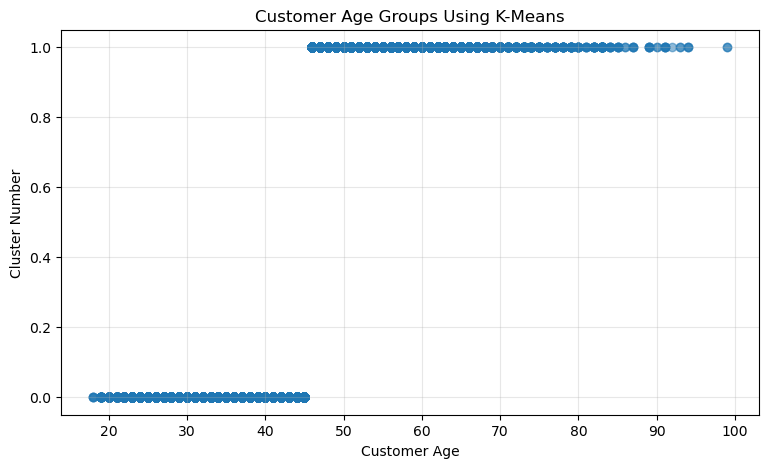

In [21]:
plt.figure(figsize=(9, 5))
plt.scatter(
    age_data['Age'],
    age_data['Cluster'],
    alpha=0.5
)
plt.xlabel('Customer Age')
plt.ylabel('Cluster Number')
plt.title('Customer Age Groups Using K-Means')
plt.grid(True, alpha=0.3)
plt.show()

Analyze clothing ratings by age group

In [22]:
rating_analysis = data.groupby('Age_Group').agg(
    Average_Rating=('Rating', 'mean'),
    Total_Reviews=('Rating', 'count'),
    Average_Feedback=('Positive Feedback Count', 'mean')
).round(2)

print(rating_analysis)

             Average_Rating  Total_Reviews  Average_Feedback
Age_Group                                                   
Age Group 1            4.18          14367              2.40
Age Group 2            4.22           9119              2.76


Analyze product recommendations

In [23]:
recommendation_analysis = data.groupby('Age_Group')[
    'Recommended IND'
].mean() * 100

recommendation_analysis = recommendation_analysis.round(2)

print("Recommendation percentage by age group:")
print(recommendation_analysis)


Recommendation percentage by age group:
Age_Group
Age Group 1    81.46
Age Group 2    83.46
Name: Recommended IND, dtype: float64


Plot the recommendation percentages

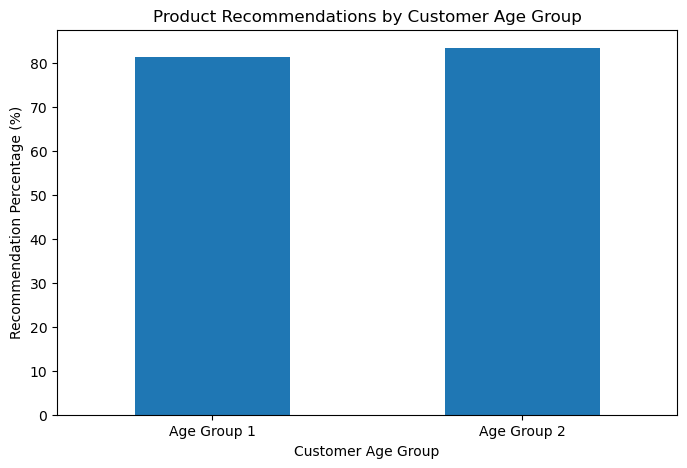

In [24]:
recommendation_analysis.plot(
    kind='bar',
    figsize=(8, 5)
)
plt.title('Product Recommendations by Customer Age Group')
plt.xlabel('Customer Age Group')
plt.ylabel('Recommendation Percentage (%)')
plt.xticks(rotation=0)
plt.show()

In [25]:
data.to_csv(
    'Womens_Clothing_With_Age_Groups.csv',
    index=False
)
print("Updated dataset saved successfully!")

Updated dataset saved successfully!
